# The Perfect Wool Coat: exploratory analysis

**Question:** does a higher wool % really mean a warmer, longer lasting coat fabric?

The data is **not** one big dataset. It is measurements I copied by hand from 4 papers
(see `data/raw/sources.md`), so the main rule is: **never mix papers** because they use
different tests and units. I compare wool % *inside* each paper.

In [1]:
import sys
sys.path.append("../src")   # so we can import our own files from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from data_loader import load_data
from data_quality import check_data, coverage_table
from feature_engineering import add_features

FIGS = Path("../outputs/figures")
FIGS.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Load and check the data

In [2]:
df = load_data()
problems = check_data(df)
print("rows:", len(df))
print("problems found:", problems if problems else "none")
df = add_features(df)
df[["paper", "wool_pct", "other_fiber", "structure", "condition"]].head()

rows: 172
problems found: none


,paper,wool_pct,other_fiber,structure,condition
0,Elshakankery 2008 (woven PES/wool),70,polyester,plain,heat set 160C
1,Elshakankery 2008 (woven PES/wool),70,polyester,plain,heat set 160C
2,Elshakankery 2008 (woven PES/wool),70,polyester,twill 2/2,heat set 160C
3,Elshakankery 2008 (woven PES/wool),70,polyester,twill 2/2,heat set 160C
4,Elshakankery 2008 (woven PES/wool),70,polyester,satin 5/2,heat set 160C


### What do we actually have?
Counts of measurements per paper and outcome. This is the key table of the project:
no paper has all the outcomes, so we can't make one big model.

In [3]:
cov = coverage_table(df)
cov

,pilling_grade,pilling_count,abrasion_result,thermal_resistance,tear_strength,rows
paper,,,,,,
Bhatia & Sinha 2021 (handloom wool/PES),0,0,0,36,0,36
Colak 2020 (acrylic/wool knit),24,0,24,24,0,24
Elshakankery 2008 (woven PES/wool),0,108,0,0,0,108
Manich (PLA or PET / wool woven),0,0,4,0,4,4


## 2. Pilling (Elshakankery 2008, woven polyester/wool, 108 samples)
Metric = pills per square inch, so **lower is better**.
Wool % is only 30 / 45 / 70, and the weave changes too, so I look at both.

In [4]:
p1 = df[df.paper.str.startswith("Elshakankery")].copy()

# mean pills by weave and wool %
table = p1.groupby(["weave_group", "wool_pct"])["pilling_count"].mean().round(1).unstack()
table

wool_pct,30,45,70
weave_group,,,
plain weave,1.5,1.3,1.2
satin,11.2,7.5,5.7
twill,6.7,4.8,3.8


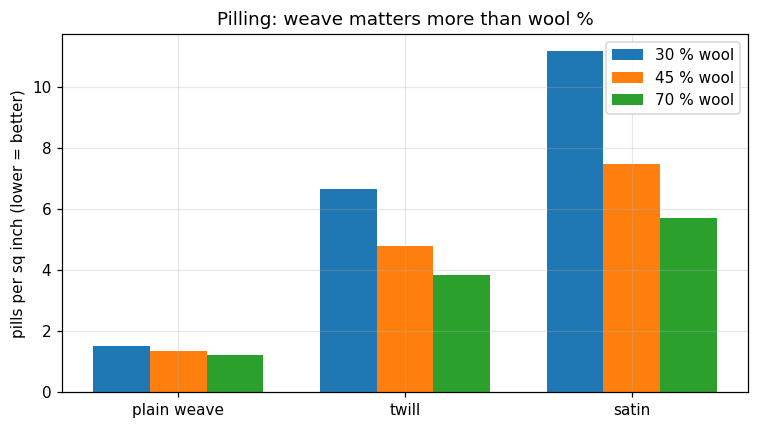

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
weaves = ["plain weave", "twill", "satin"]
levels = [30, 45, 70]
width = 0.25
for i, w in enumerate(levels):
    vals = [p1[(p1.weave_group == wv) & (p1.wool_pct == w)]["pilling_count"].mean() for wv in weaves]
    ax.bar(np.arange(3) + i * width, vals, width, label=f"{w} % wool")
ax.set_xticks(np.arange(3) + width)
ax.set_xticklabels(weaves)
ax.set_ylabel("pills per sq inch (lower = better)")
ax.set_title("Pilling: weave matters more than wool %")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "fig1_pilling_by_weave_and_wool.png")
plt.show()

### How big is the wool effect compared with the weave effect?
Small regression (ordinary least squares with numpy). Plain weave and 160 C heat set are the baseline.
The coefficients are in **pills per sq inch**.

In [6]:
X = pd.get_dummies(p1[["weave_group"]], drop_first=True).astype(float)
X["wool_per_10pct"] = p1["wool_pct"] / 10
X["heat_set_180C"] = (p1["condition"] == "heat set 180C").astype(float)
X.insert(0, "intercept", 1.0)

y = p1["pilling_count"].values
beta, *_ = np.linalg.lstsq(X.values, y, rcond=None)

pred = X.values @ beta
r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

coefs = pd.Series(beta, index=X.columns).round(2)
print(coefs)
print("R squared:", round(r2, 2))

intercept            4.80
weave_group_satin    6.76
weave_group_twill    3.74
wool_per_10pct      -0.68
heat_set_180C       -0.27
dtype: float64
R squared: 0.6


**Reading it:** going from plain to satin adds a lot more pills than 10 % more wool removes.
(The samples in this paper are not independent, e.g. the same yarn is used in several fabrics, so I would not
trust the exact numbers, only the size order.)

## 3. Warmth (Bhatia & Sinha 2021, handloom wool/polyester, Clo)
Higher Clo = warmer. Only the **weft** changes in these fabrics (the warp is the same), and the wool %
is the weft yarn blend. BT = before PVA removal, AT / ATY = after the PVA was dissolved.

In [7]:
p2 = df[df.paper.str.startswith("Bhatia")].copy()
p2["stage"] = p2["condition"].str.split(" ").str[0]

mean_clo = p2.groupby(["wool_pct", "stage"])["thermal_resistance"].mean().unstack()
mean_clo.round(3)

stage,AT,ATY,BT
wool_pct,,,
30,0.186,0.160,0.140
45,0.200,0.170,0.140
50,0.180,0.160,0.150
60,0.210,0.180,0.160
65,0.210,0.180,0.160
70,0.195,0.175,0.165


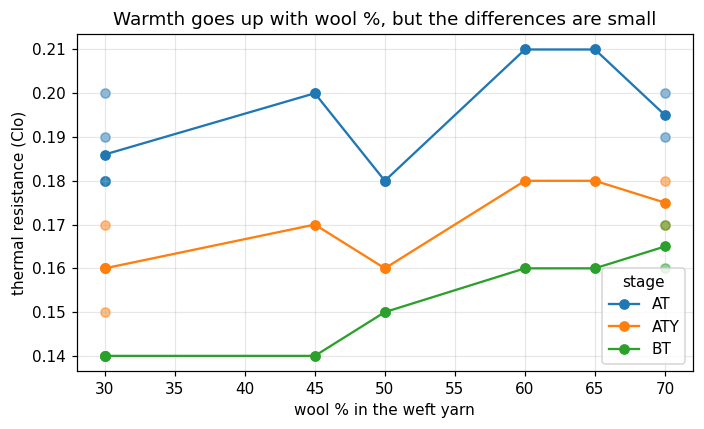

AT: r = 0.51  (n = 12)
ATY: r = 0.73  (n = 12)
BT: r = 0.95  (n = 12)


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for stage, g in p2.groupby("stage"):
    ax.scatter(g["wool_pct"], g["thermal_resistance"], alpha=0.5)
    m = g.groupby("wool_pct")["thermal_resistance"].mean()
    ax.plot(m.index, m.values, marker="o", label=stage)
ax.set_xlabel("wool % in the weft yarn")
ax.set_ylabel("thermal resistance (Clo)")
ax.set_title("Warmth goes up with wool %, but the differences are small")
ax.legend(title="stage")
fig.tight_layout()
fig.savefig(FIGS / "fig2_thermal_vs_wool.png")
plt.show()

for stage, g in p2.groupby("stage"):
    r = g["wool_pct"].corr(g["thermal_resistance"])
    print(f"{stage}: r = {r:.2f}  (n = {len(g)})")

## 4. Knitted acrylic/wool (Colak 2020 thesis)
3 denier fabrics, wool 0 / 10 / 30 / 50 %. Each wool % was made at 4 relax / high-bulk levels.
Abrasion = mass loss % (**lower is better**). Pilling grade 1-5 (**higher is better**).
Thermal resistance is in 1e-3 K m2/W (a different unit from the Clo values above!).

In [9]:
p3 = df[df.paper.str.startswith("Colak")].copy()
p3 = p3[p3.condition.str.startswith("3 denier")].copy()
p3["relax_level"] = p3["condition"].str.replace("3 denier, ", "", regex=False)

by_wool = p3.groupby("wool_pct")[["pilling_grade", "abrasion_result", "thermal_resistance"]].mean().round(2)
by_wool

,pilling_grade,abrasion_result,thermal_resistance
wool_pct,,,
0,2.12,15.90,25.25
10,1.38,11.25,25.10
30,1.62,11.42,24.92
50,1.25,11.55,25.12


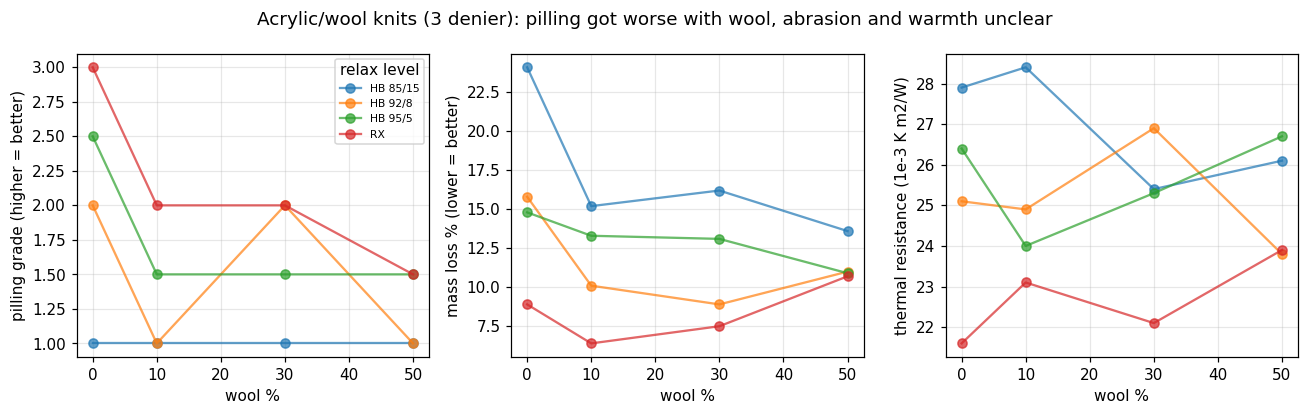

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
cols = [("pilling_grade", "pilling grade (higher = better)"),
        ("abrasion_result", "mass loss % (lower = better)"),
        ("thermal_resistance", "thermal resistance (1e-3 K m2/W)")]
for ax, (col, label) in zip(axes, cols):
    for rl, g in p3.groupby("relax_level"):
        ax.plot(g["wool_pct"], g[col], marker="o", alpha=0.7, label=rl)
    ax.set_xlabel("wool %")
    ax.set_ylabel(label)
axes[0].legend(title="relax level", fontsize=7)
fig.suptitle("Acrylic/wool knits (3 denier): pilling got worse with wool, abrasion and warmth unclear")
fig.tight_layout()
fig.savefig(FIGS / "fig3_colak_knits.png")
plt.show()

The lines are all over the place, because with only 4 points per line and one measurement per fabric
we can't separate the wool effect from noise. Another thing I noticed: the **relax level** (how bulky the yarn is)
seems to change thermal resistance more than the wool % does. Quick check:

In [11]:
p3.groupby("relax_level")["thermal_resistance"].mean().round(1)

relax_level
HB 85/15    27.0
HB 92/8     25.2
HB 95/5     25.6
RX          22.7
Name: thermal_resistance, dtype: float64

## 5. The other fibre matters too (Manich et al., woven, 45 % wool)
Same wool % (45) but the other 55 % is polyester (PET) or polylactide (PLA). Washed and heat set fabrics.

In [12]:
p4 = df[df.paper.str.startswith("Manich")].copy()
p4["label"] = p4["other_fiber"] + " / " + p4["weave_group"]
p4[["label", "gsm", "abrasion_result", "tear_strength"]].round(1)

,label,gsm,abrasion_result,tear_strength
168,polylactide / plain weave,163.8,34.0,15.3
169,polylactide / twill,191.5,73.2,20.1
170,polyester / plain weave,159.8,13.9,20.6
171,polyester / twill,195.3,3.3,25.4


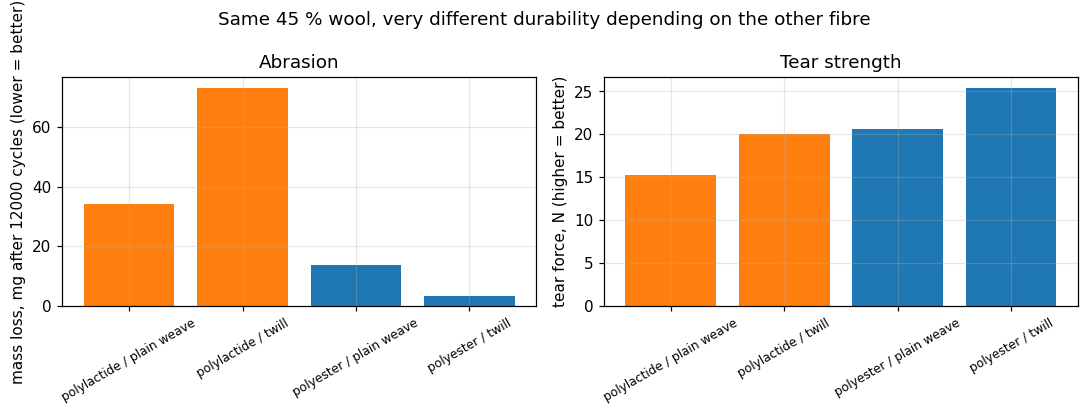

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(p4["label"], p4["abrasion_result"], color=["tab:orange"] * 2 + ["tab:blue"] * 2)
axes[0].set_ylabel("mass loss, mg after 12000 cycles (lower = better)")
axes[0].set_title("Abrasion")
axes[1].bar(p4["label"], p4["tear_strength"], color=["tab:orange"] * 2 + ["tab:blue"] * 2)
axes[1].set_ylabel("tear force, N (higher = better)")
axes[1].set_title("Tear strength")
for ax in axes:
    ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.suptitle("Same 45 % wool, very different durability depending on the other fibre")
fig.tight_layout()
fig.savefig(FIGS / "fig4_other_fibre_matters.png")
plt.show()

## 6. Putting it together
One summary table of what each paper says about wool % (inside that paper only).

In [14]:
summary = pd.DataFrame([
    ["Elshakankery 2008", "woven PES/wool", "pilling (pills/sq in)", "30-70 %", "more wool = fewer pills, but weave effect is bigger"],
    ["Bhatia & Sinha 2021", "handloom wool/PES", "warmth (Clo)", "30-70 % (weft only)", "more wool = warmer, small differences"],
    ["Colak 2020", "acrylic/wool knit", "pilling, abrasion, warmth", "0-50 %", "pilling grade lower (worse) with wool, abrasion and warmth unclear, bulkiness matters"],
    ["Manich et al.", "woven PES or PLA / wool", "abrasion, tear", "45 % only", "other fibre changes durability a lot"],
], columns=["paper", "fabric", "outcome(s)", "wool % range", "what we see"])
summary

,paper,fabric,outcome(s),wool % range,what we see
0,Elshakankery 2008,woven PES/wool,pilling (pills/sq in),30-70 %,"more wool = fewer pills, but weave effect is b..."
1,Bhatia & Sinha 2021,handloom wool/PES,warmth (Clo),30-70 % (weft only),"more wool = warmer, small differences"
2,Colak 2020,acrylic/wool knit,"pilling, abrasion, warmth",0-50 %,"pilling grade lower (worse) with wool, abrasio..."
3,Manich et al.,woven PES or PLA / wool,"abrasion, tear",45 % only,other fibre changes durability a lot


In [15]:
summary.to_csv("../outputs/summary_table.csv", index=False)
print("saved outputs/summary_table.csv")

saved outputs/summary_table.csv


## 7. Conclusions (what I can and can't say)

**What the data supports**
- Wool % does **not** automatically decide performance. In every paper something else mattered as much or more
  (weave, how the yarn was made, what the other fibre is).
- In the woven polyester/wool fabrics, more wool went with less pilling. In the handloom fabrics, more wool went with
  slightly higher thermal resistance.
- In the acrylic/wool knits pilling grade was actually lower (worse) with wool, and abrasion and warmth showed no clear trend.
- Weave matters a lot for pilling: plain and twill pilled much less than satin at every wool %.
- The other fibre matters a lot for abrasion and tear strength (polyester vs polylactide at the same 45 % wool).

**What it can't say**
- No paper measured pilling, abrasion and warmth on the same fabrics, so I can't say which wool % is best overall.
- Only 4 papers, and some are old or from industry sources. Different test methods and units, so no pooling.
- Wool % comes in only a few levels per paper and the fabrics are not independent samples, so the numbers are
  rough. The regression is only a size comparison, not a proof.
- Nothing here measures real coat lifespan.

**Practical takeaways for choosing a coat fabric (tentative)**
1. Look at the weave and finish, not only the wool %: a plain or twill weave pills less than satin.
2. If the wool is blended, ask what the other fibre is. It can change abrasion and tear resistance a lot.
3. For warmth, wool does seem to help, but thickness and how bulky the yarn is probably matter too.

**Next steps:** find more papers with tear and abrasion data on woven fabrics where wool % is varied
(this project uses published literature data only), and optionally use a pilling image dataset in a separate
computer vision mini-project.